## Data View

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("/home/ec2-user/studies/HUIFA-RNA-SEQ-new/Project/2026-nc-final").resolve()
DATASETS_DIR = (Path("/home/ec2-user/studies") / "hpp_datasets").resolve()

sys.path.append(str(PROJECT_DIR))

from phenokit.preprocessing.qc import MissingValueAnalyzer
from phenokit.preprocessing.io import read_parquet

pfile = DATASETS_DIR / "serum_lipidomics" / "serum_lipidomics.parquet"
df_lipid = read_parquet(str(pfile))
print(df_lipid.shape)
df_lipid.head()

(6321, 194)


,participant_id,cohort,research_stage,array_index,collection_date,collection_timestamp,timezone,22:6_cholesteryl_ester,acca_c10:0,acca_c16:0,...,lysopc_18:1,lysopc_18:2,lysopc_18:3,lysopc_20:0,lysopc_20:1,lysopc_22:6,lysope_16:0,lysope_18:0,lysope_18:1,lysope_18:2
0,2578644992,10k,00_00_visit,0,2021-04-05,2021-04-05 09:52:43+03:00,asia/jerusalem,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1321172995,10k,00_00_visit,0,2021-07-14,2021-07-14 12:38:41+03:00,asia/jerusalem,0.816471,0.344327,0.811598,...,0.189252,0.613851,NaN,0.128019,0.101897,0.591244,NaN,NaN,0.402797,0.750045
2,1802502158,10k,00_00_visit,0,2020-01-15,2020-01-15 13:12:52+02:00,asia/jerusalem,1.155827,0.741570,0.345470,...,0.148123,0.538003,NaN,0.147741,0.116392,0.475901,0.143813,0.071135,0.278811,0.725242
3,2283962386,10k,00_00_visit,0,2021-03-01,2021-03-01 08:22:55+02:00,asia/jerusalem,0.703909,0.398315,0.670082,...,NaN,NaN,NaN,0.233832,0.155598,0.558033,0.104346,0.076463,0.430089,1.063132
4,9564913685,10k,00_00_visit,0,2021-06-22,2021-06-22 10:43:23+03:00,asia/jerusalem,1.803044,NaN,NaN,...,0.088257,0.398680,NaN,0.077516,0.056696,0.497207,0.053589,0.020101,0.494636,0.256811


Overall missing rate: 0.1920 (235449 out of 1226274)
=== Feature missing-rate report. (Top 10) ===
                 missing_rate  missing_count
cer_d18:1/c24:0      0.985287           6228
tag_57:8             0.985287           6228
pc_34:1              0.970732           6136
tag_54:3             0.927385           5862
dag_36:5             0.913621           5775
tag_60:2             0.899067           5683
tag_58:1             0.899067           5683
cer_d18:0/c16:0      0.841006           5316
tag_51:6             0.813795           5144
dag_32:1             0.753362           4762
=== Sample missing-rate report. (Top 10) ===
      missing_rate  missing_count
6211      0.824742            160
6163      0.824742            160
587       0.824742            160
1397      0.824742            160
5875      0.824742            160
5856      0.824742            160
59        0.824742            160
5838      0.824742            160
5829      0.824742            160
940       0.824742   

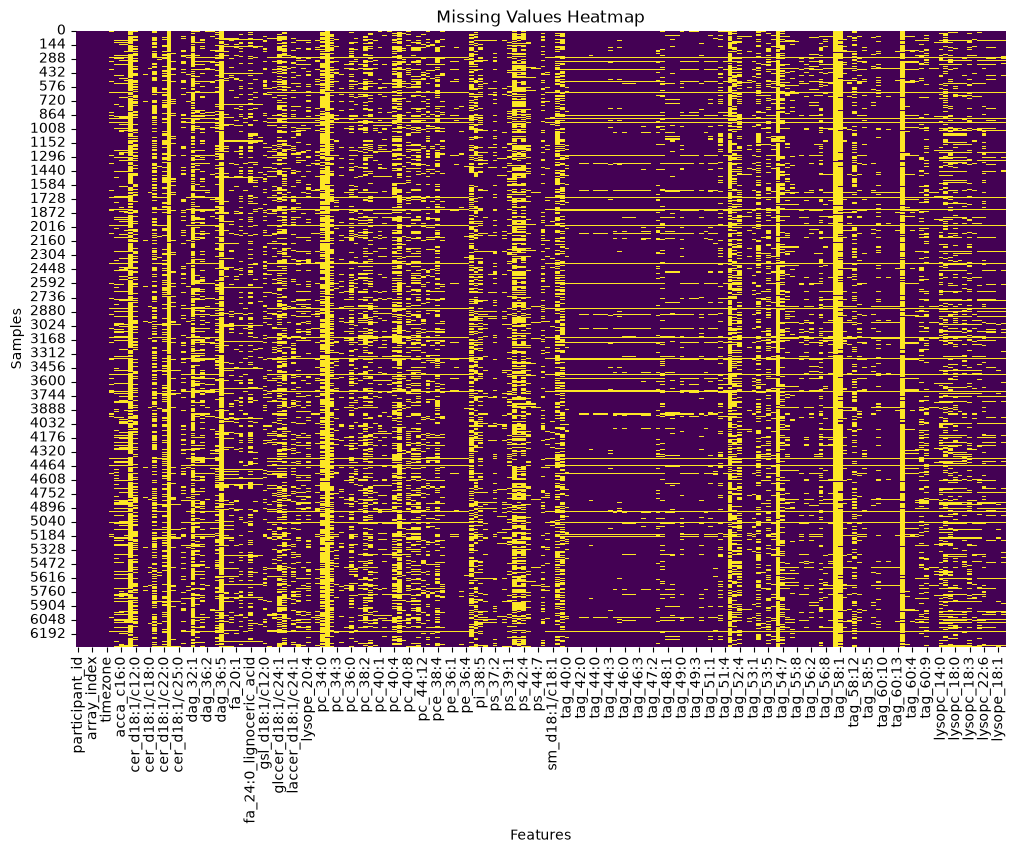

In [2]:
# Check the number and proportion of missing values
missing_analyzer = MissingValueAnalyzer(df_lipid)
missing_analyzer.overall_missing_rate()
missing_analyzer.report_features()
missing_analyzer.report_samples()
missing_analyzer.report_heatmap()

## Missing Value Handling

In [3]:
metadata_col = ['participant_id', 'cohort', 'research_stage', 'array_index', 'collection_date', 'collection_timestamp', 'timezone']
df_lipid_metadata = df_lipid[metadata_col]
df_lipid_features = df_lipid.drop(columns=metadata_col)

### Feature Filtering

In [4]:
# 假设 df_lipid_features 是你的原始数据
missing_ratio_per_feature = df_lipid_features.isnull().sum() / len(df_lipid_features)  # 计算每列的缺失值比例
feature_threshold = 0.7  # 设定特征缺失率阈值

# 剔除缺失率超过阈值的特征
df_lipid_features = df_lipid_features.loc[:, missing_ratio_per_feature <= feature_threshold]
print(df_lipid_features.shape)

(6321, 177)


In [5]:
df_lipid_features.to_csv('interim_data/008-serum_lipidomics_feature_filtered.csv', index=False)

In [6]:
df_lipid_features_columns = df_lipid_features.columns.tolist()
df_lipid_features.columns = [str(i) for i in range(len(df_lipid_features.columns))]

### Imputation

In [ ]:
# R:
# library(imputeLCMD)
# set.seed(123)

# offset <- 1e-6            # 或者 1、0.5，看你数据单位
# x_raw <- read.csv("/home/ec2-user/studies/HUIFA-RNA-SEQ-new/phenoAI/01-preprocessing/pheno_data/202512/008-serum_lipidomics_feature_filtered.csv", header = TRUE, stringsAsFactors = FALSE)
# x_log <- log2(x_raw + offset)

# x_log_imp <- impute.QRILC(x_log)[[1]]  # 使用 QRILC 方法进行缺失值填补
# x_imp_raw <- 2^x_log_imp - offset  # 如果一开始加了 offset，这里减回去

# rownames(x_imp_raw) <- rownames(x_raw)
# colnames(x_imp_raw) <- colnames(x_raw)

# write.csv(x_imp_raw, "/home/ec2-user/studies/HUIFA-RNA-SEQ-new/phenoAI/01-preprocessing/pheno_data/202512/008-serum_lipidomics_feature_imputed.csv", row.names = FALSE)

## Save

In [7]:
df_lipid_features = pd.read_csv('interim_data/008-serum_lipidomics_feature_imputed.csv')

In [8]:
df_lipid_metadata.reset_index(drop=True, inplace=True)
df_lipid = pd.concat([df_lipid_metadata, df_lipid_features], axis=1)
df_lipid.to_parquet('processed_data/008-serum_lipidomics_imputed.parquet')

In [9]:
pfile = 'processed_data/008-serum_lipidomics_imputed.parquet'
df_lipid = pd.read_parquet(pfile)
print(df_lipid.shape)
df_lipid.head()

(6321, 184)


,participant_id,cohort,research_stage,array_index,collection_date,collection_timestamp,timezone,X22.6_cholesteryl_ester,acca_c10.0,acca_c16.0,...,lysopc_18.1,lysopc_18.2,lysopc_18.3,lysopc_20.0,lysopc_20.1,lysopc_22.6,lysope_16.0,lysope_18.0,lysope_18.1,lysope_18.2
0,2578644992,10k,00_00_visit,0,2021-04-05,2021-04-05 09:52:43+03:00,asia/jerusalem,0.260245,0.076244,0.223159,...,0.078844,0.310100,0.181093,0.053899,0.027059,0.219445,0.061405,0.034036,0.128355,0.354275
1,1321172995,10k,00_00_visit,0,2021-07-14,2021-07-14 12:38:41+03:00,asia/jerusalem,0.816471,0.344327,0.811598,...,0.189252,0.613851,0.125260,0.128019,0.101897,0.591244,0.059292,0.021701,0.402797,0.750045
2,1802502158,10k,00_00_visit,0,2020-01-15,2020-01-15 13:12:52+02:00,asia/jerusalem,1.155827,0.741570,0.345470,...,0.148123,0.538003,0.151963,0.147741,0.116392,0.475901,0.143813,0.071135,0.278811,0.725242
3,2283962386,10k,00_00_visit,0,2021-03-01,2021-03-01 08:22:55+02:00,asia/jerusalem,0.703909,0.398315,0.670082,...,0.066388,0.221997,0.159303,0.233832,0.155598,0.558033,0.104346,0.076463,0.430089,1.063132
4,9564913685,10k,00_00_visit,0,2021-06-22,2021-06-22 10:43:23+03:00,asia/jerusalem,1.803044,0.065956,0.221179,...,0.088257,0.398680,0.053214,0.077516,0.056696,0.497207,0.053589,0.020101,0.494636,0.256811
